# 03. Análise de sazonalidade dos alimentos
**Integrante 3 — Segunda pergunta de pesquisa:** a época do ano influencia os preços?

Este notebook executa a análise completa e apresenta resultados, gráficos e conclusão. Lê apenas a base tratada anteriormente; grava somente nas pastas exclusivas de sazonalidade. Execute de cima para baixo com as dependências de `requirements.txt`.

In [1]:
from pathlib import Path
import sys
from importlib import import_module
from IPython.display import display, Markdown, Image
ROOT = Path.cwd().resolve()
if not (ROOT / "src/sazonalidade.py").exists():
    ROOT = ROOT.parent
assert (ROOT / "src/sazonalidade.py").exists(), "Abra o notebook na raiz ou na pasta notebooks."
sys.path.insert(0, str(ROOT / "src"))
sazonalidade = import_module("sazonalidade")
OUT, FIG = sazonalidade.OUT, sazonalidade.FIG
cobertura, testes, perfis, componentes = sazonalidade.main()

                produto     q_bh mes_menor mes_maior  estavel_sensibilidade
                 Tomate 0.000363       Out       Abr                   True
                  Leite 0.020365       Jan       Jul                   True
                 Feijão 0.051100       Nov       Mai                  False
          Banana Nanica 0.072527       Mai       Nov                  False
       Farinha de Trigo 0.090652       Mai       Nov                  False
                   Óleo 0.249031       Jul       Jan                  False
           Banana Prata 0.322652       Ago       Fev                  False
                 Batata 0.352368       Nov       Mai                  False
            Pão Francês 0.955538       Nov       Mai                  False
                  Arroz 0.983030       Ago       Fev                  False
                 Açúcar 0.983030       Mai       Nov                  False
                   Café 0.983030       Jul       Jan                  False
Carne Bovina

## 1. Cobertura e elegibilidade
São necessários pelo menos 36 meses consecutivos. Não interpolamos valores nem tratamos as coletas de um mesmo mês como observações temporais independentes. Séries de 18 meses ficam fora da inferência.

,produto,inicio,fim,n_meses,meses_ausentes,minimo_repeticoes_mes,min_coletas,max_coletas,elegivel
0,Arroz,2022-09-01,2026-08-01,48,0,4,73,126,True
1,Açúcar,2022-09-01,2026-08-01,48,0,4,30,81,True
2,Banana Nanica,2022-09-01,2026-08-01,48,0,4,8,30,True
3,Banana Prata,2022-09-01,2026-08-01,48,0,4,12,29,True
4,Batata,2022-09-01,2026-08-01,48,0,4,18,31,True
5,Café,2022-09-01,2026-08-01,48,0,4,67,134,True
6,Carne Bovina Acém,2025-03-01,2026-08-01,18,0,1,18,27,False
7,Carne Bovina Coxão Mole,2022-09-01,2026-08-01,48,0,4,18,29,True
8,Carne Suína Pernil,2025-03-01,2026-08-01,18,0,1,17,28,False
9,Farinha de Trigo,2022-09-01,2026-08-01,48,0,4,60,103,True


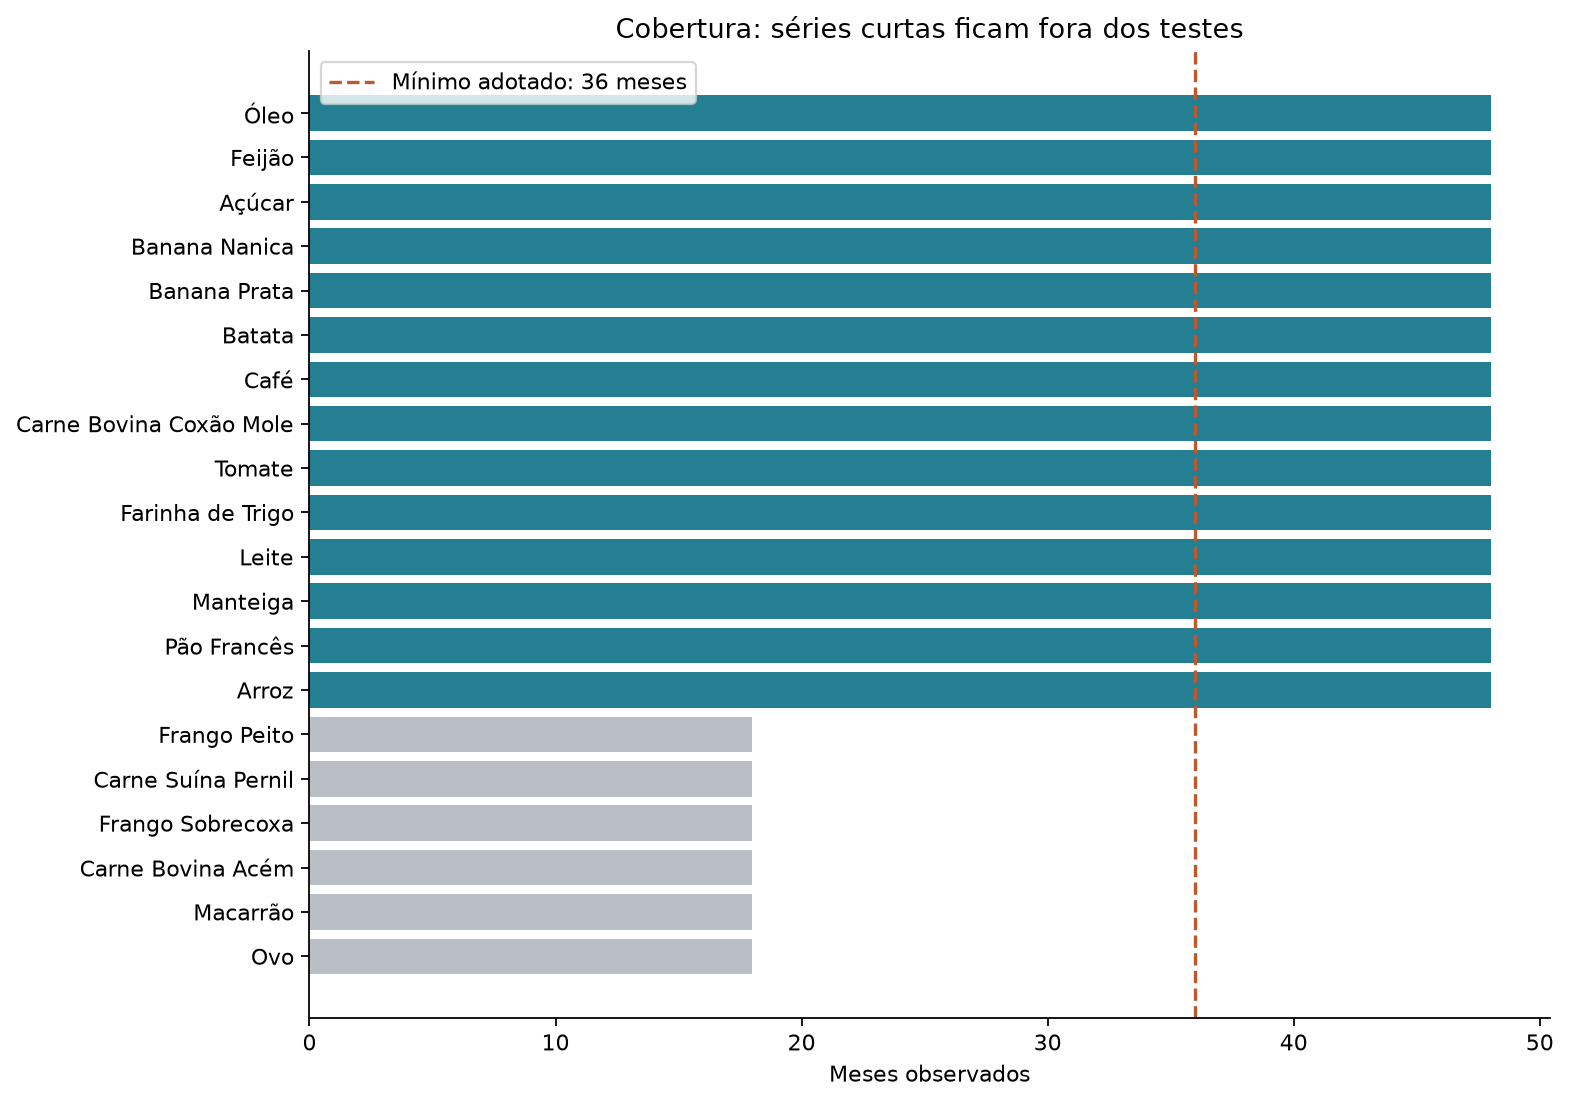

In [2]:
display(cobertura)
display(Image(filename=str(FIG / "01_cobertura.png")))

## 2. Variação entre meses e anos
Os preços são nominais. A tendência STL permite visualizar movimentos de longo prazo. Os anos inicial e final são parciais: comparar suas médias diretamente pode confundir composição dos meses e mudança de preço.

,produto,ano,media_ppk,minimo_ppk,maximo_ppk,meses_observados
0,Arroz,2022,4.908750,4.788000,4.998000,4
1,Arroz,2023,5.322250,4.998000,5.998000,12
2,Arroz,2024,6.736167,6.398000,6.888000,12
3,Arroz,2025,5.975083,5.098000,6.780000,12
4,Arroz,2026,5.052250,4.878000,5.198000,8
...,...,...,...,...,...,...
77,Óleo,2022,9.225000,9.055556,9.433333,4
78,Óleo,2023,7.439352,6.322222,9.500000,12
79,Óleo,2024,7.283333,6.433333,9.377778,12
80,Óleo,2025,9.018063,8.544444,9.655600,12


,produto,mes_num,media_ppk,mediana_ppk,desvio_ppk,n_anos
0,Arroz,1,5.863750,5.798000,0.853228,4
1,Arroz,2,5.963750,5.940000,0.906422,4
2,Arroz,3,5.806250,5.829500,0.949483,4
3,Arroz,4,5.750500,5.703000,0.856402,4
4,Arroz,5,5.772250,5.673500,0.807685,4
...,...,...,...,...,...,...
235,Óleo,8,7.738889,7.877778,1.031899,4
236,Óleo,9,8.037500,8.141667,1.359764,4
237,Óleo,10,8.183333,8.488889,1.364979,4
238,Óleo,11,8.472233,8.955556,1.473104,4


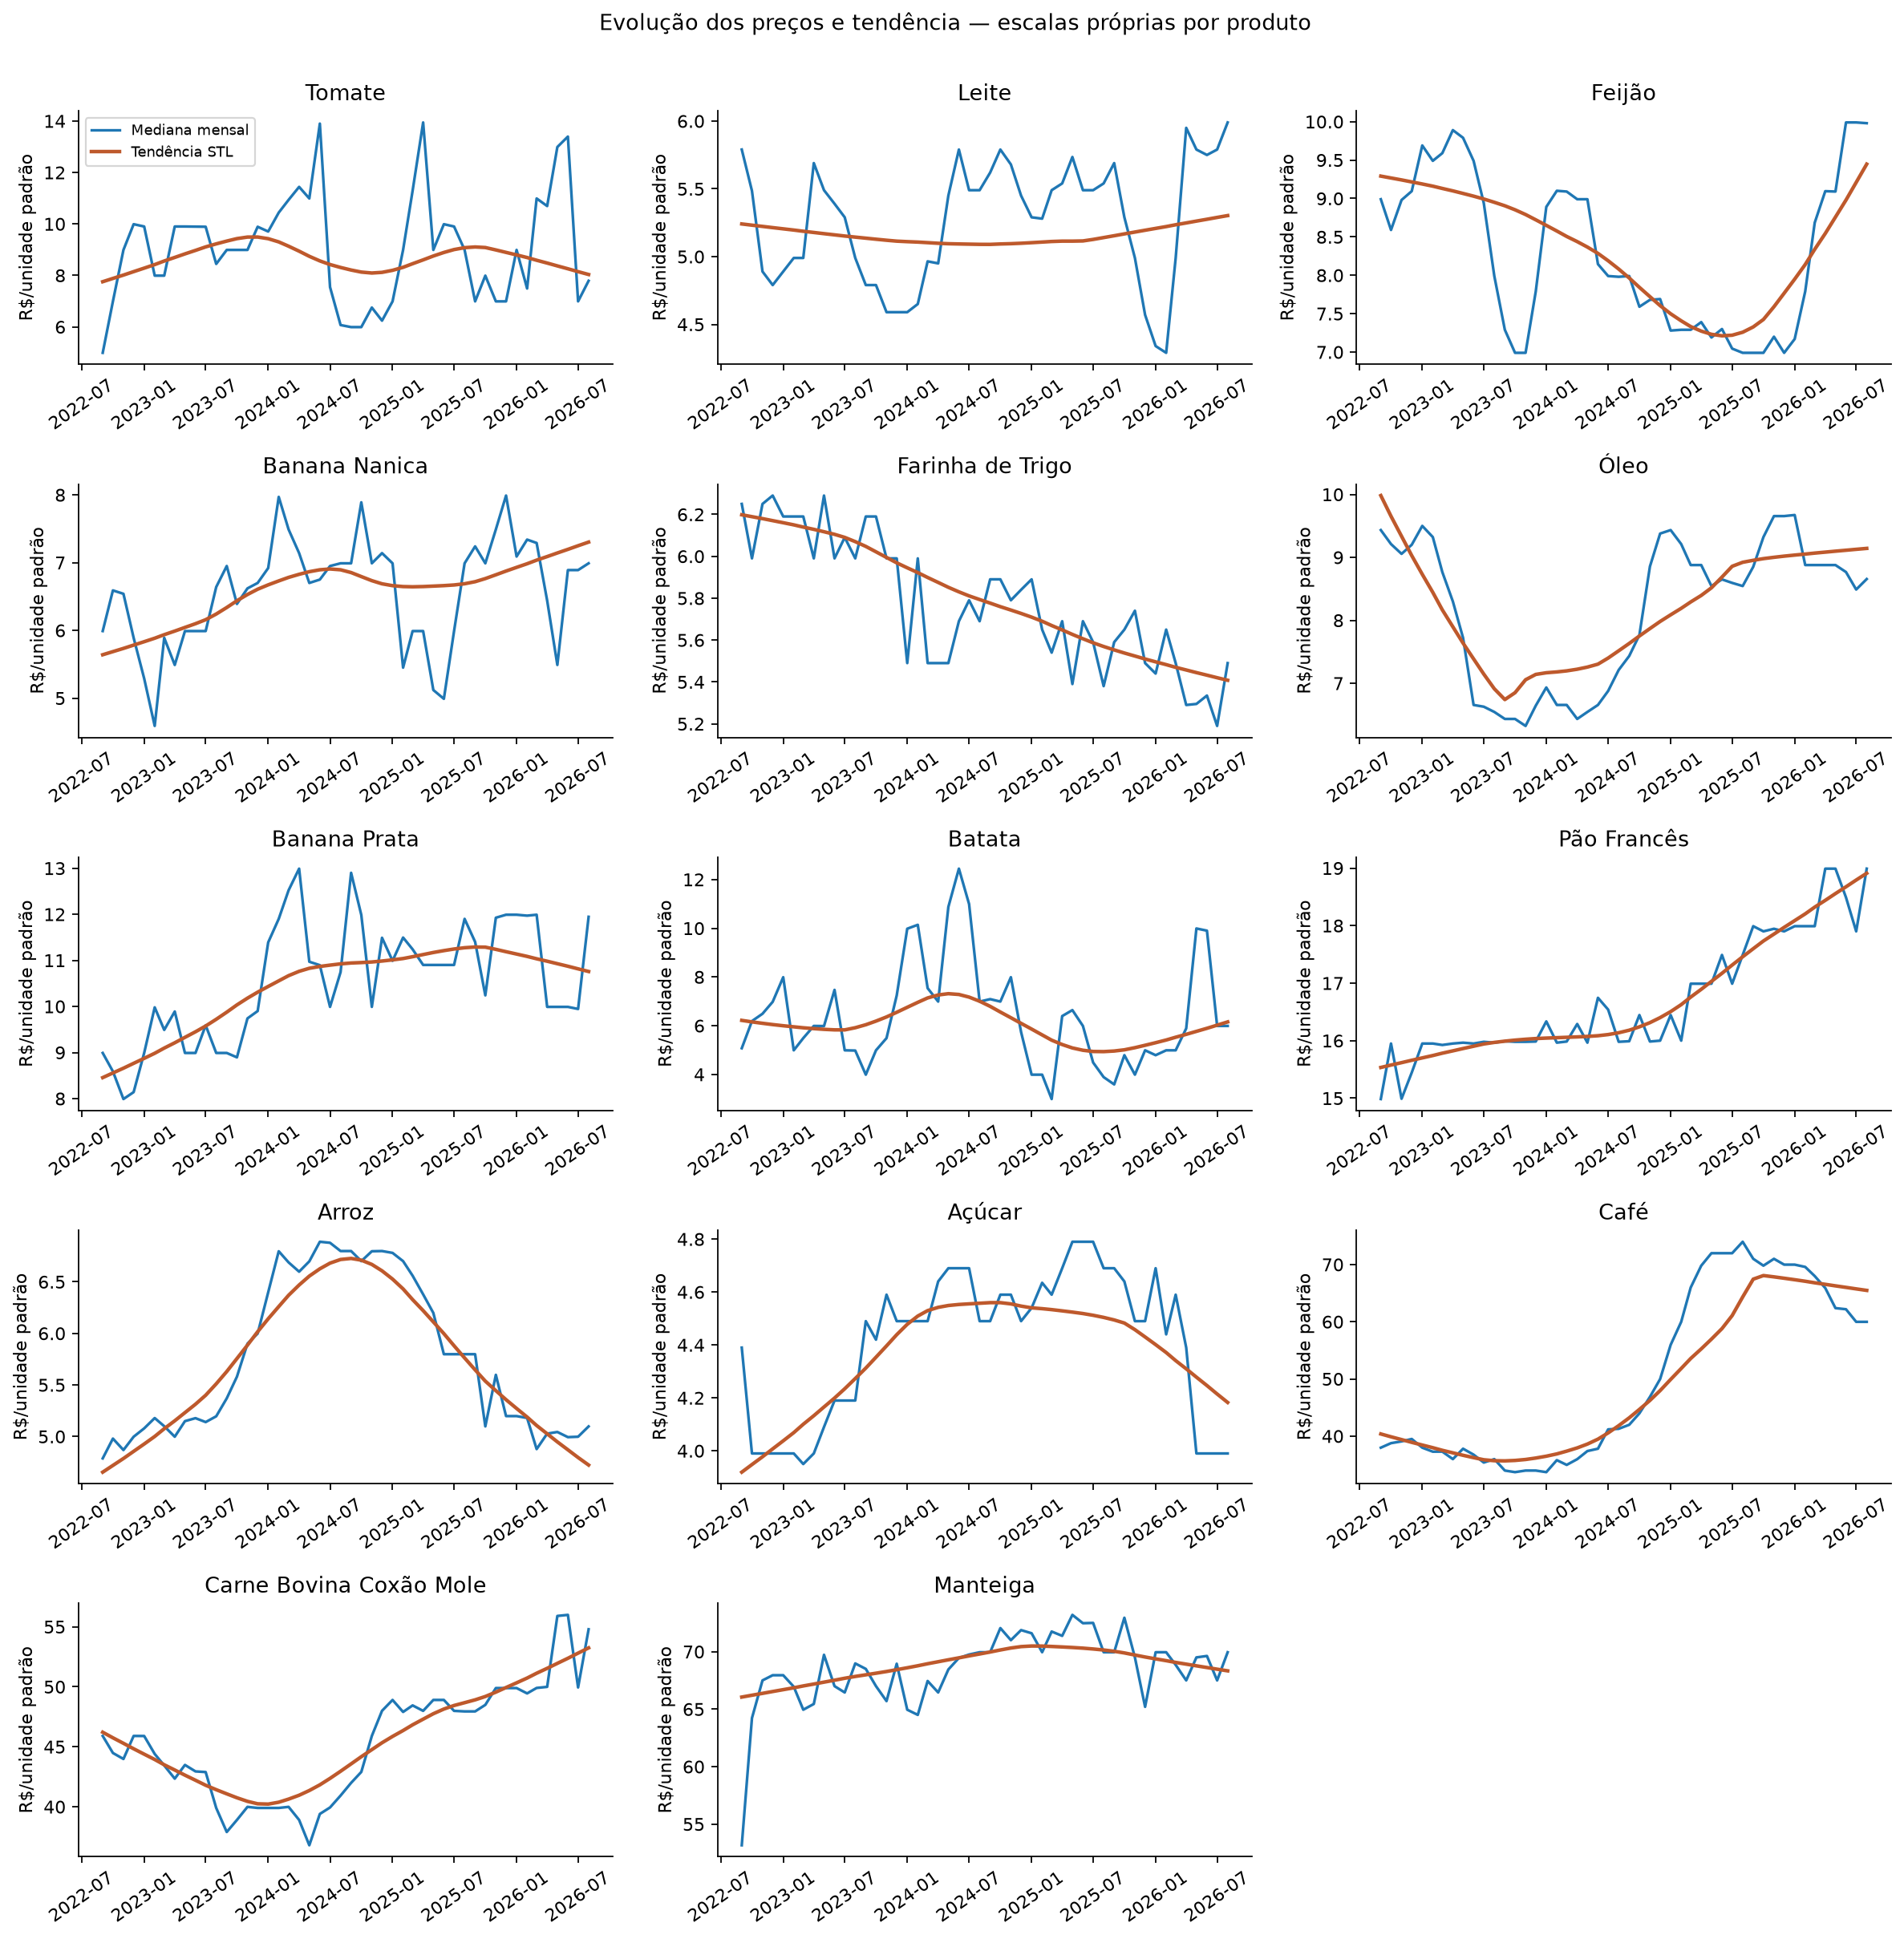

In [3]:
import pandas as pd
display(pd.read_csv(OUT / "resumo_anual.csv"))
display(pd.read_csv(OUT / "resumo_mensal_bruto.csv"))
display(Image(filename=str(FIG / "02_evolucao_tendencia.png")))

## 3. Teste de ciclo anual com controle de tendência
A regressão usa log-preço, tendência linear e seno/cosseno com período de 12 meses. Testamos conjuntamente a ausência dos dois termos sazonais com covariância HAC de 3 defasagens. Corrigimos os testes entre produtos por Benjamini–Hochberg: **q < 0,05** é o limiar exploratório.

As sensibilidades alteram separadamente a tendência para quadrática e a covariância para HAC com 6 defasagens. A coluna `estavel_sensibilidade` exige significância nas três especificações. Os testes são aproximados com apenas quatro ciclos; o relatório detalha as limitações.

,produto,n_meses,p_hac3,p_tendencia_quadratica,p_hac6,mes_menor,mes_maior,amplitude_pico_vale_pct,forca_stl,r2,p_ljungbox12,q_bh,q_quadratica,q_hac6,evidencia_principal,estavel_sensibilidade
12,Tomate,48,0.00003,0.00005,0.00030,Out,Abr,55.18549,0.73891,0.44502,0.25994,0.00036,0.00065,0.00416,True,True
9,Leite,48,0.00291,0.00361,0.00512,Jan,Jul,16.83442,0.42751,0.45219,0.00000,0.02037,0.01686,0.03586,True,True
8,Feijão,48,0.01095,0.00076,0.01650,Nov,Mai,17.68836,0.53540,0.31424,0.00000,0.05110,0.00534,0.07701,False,False
2,Banana Nanica,48,0.02072,0.01215,0.03363,Mai,Nov,16.90301,0.48211,0.29913,0.00005,0.07253,0.04251,0.09418,False,False
7,Farinha de Trigo,48,0.03238,0.03165,0.02203,Mai,Nov,3.54830,0.31809,0.76914,0.02283,0.09065,0.08861,0.07712,False,False
13,Óleo,48,0.10673,0.04673,0.06041,Jul,Jan,16.40093,0.38480,0.26089,0.00000,0.24903,0.10903,0.14096,False,False
3,Banana Prata,48,0.16133,0.06426,0.15306,Ago,Fev,8.79216,0.51019,0.43321,0.00183,0.32265,0.12853,0.28791,False,False
4,Batata,48,0.20135,0.19521,0.16452,Nov,Mai,32.27727,0.42743,0.11586,0.00000,0.35237,0.34162,0.28791,False,False
11,Pão Francês,48,0.61427,0.34605,0.61705,Nov,Mai,1.50354,0.59112,0.82588,0.00000,0.95554,0.53830,0.95986,False,False
0,Arroz,48,0.93121,0.92606,0.91731,Ago,Fev,3.39331,0.55411,0.01332,0.00000,0.98303,0.98087,0.97703,False,False


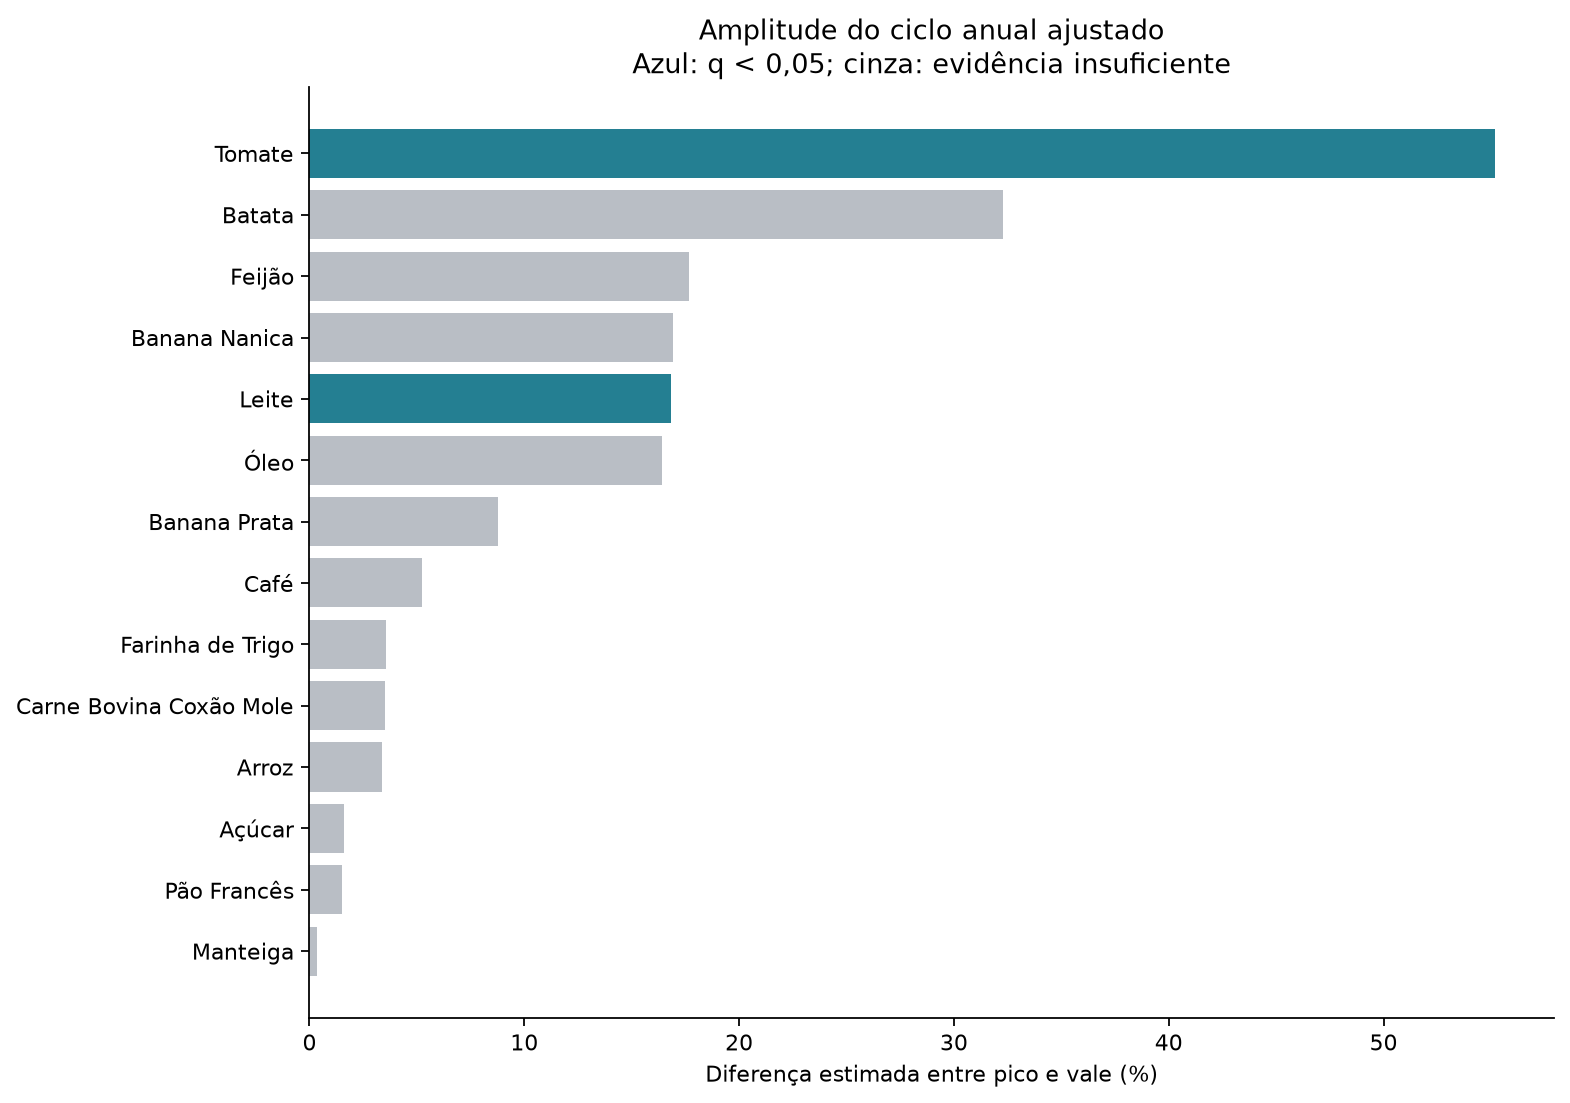

In [4]:
display(testes.round(5))
display(Image(filename=str(FIG / "04_amplitudes.png")))

## 4. Períodos de preço maior e menor
O calendário mostra o ciclo harmônico após controlar a tendência. Índice 100 representa o nível sem o ciclo anual. Meses extremos são estimativas do modelo, não garantias de economia. Produtos sem evidência estatística não devem receber uma recomendação sazonal a partir deste ajuste.

A Parte 5 usa o índice harmônico como referência histórica. Ao comparar seu vale com o menor preço previsto, consulte também `evidencia_principal` e `estavel_sensibilidade` na tabela acima. Para os produtos fora do teste ou sem evidência no teste principal, a comparação tem caráter descritivo.

,produto,mes_num,mes,n_anos,media_nominal,mediana_nominal,indice_harmonico,efeito_stl_pct
0,Arroz,1,Jan,4,5.864,5.798,101.499,1.956
1,Arroz,2,Fev,4,5.964,5.940,101.683,3.182
2,Arroz,3,Mar,4,5.806,5.829,101.412,0.143
3,Arroz,4,Abr,4,5.750,5.703,100.763,-0.105
4,Arroz,5,Mai,4,5.772,5.674,99.914,0.576
...,...,...,...,...,...,...,...,...
163,Óleo,8,Ago,4,7.739,7.878,94.522,-4.801
164,Óleo,9,Set,4,8.037,8.142,97.859,-3.465
165,Óleo,10,Out,4,8.183,8.489,101.903,-0.699
166,Óleo,11,Nov,4,8.472,8.956,105.580,2.000


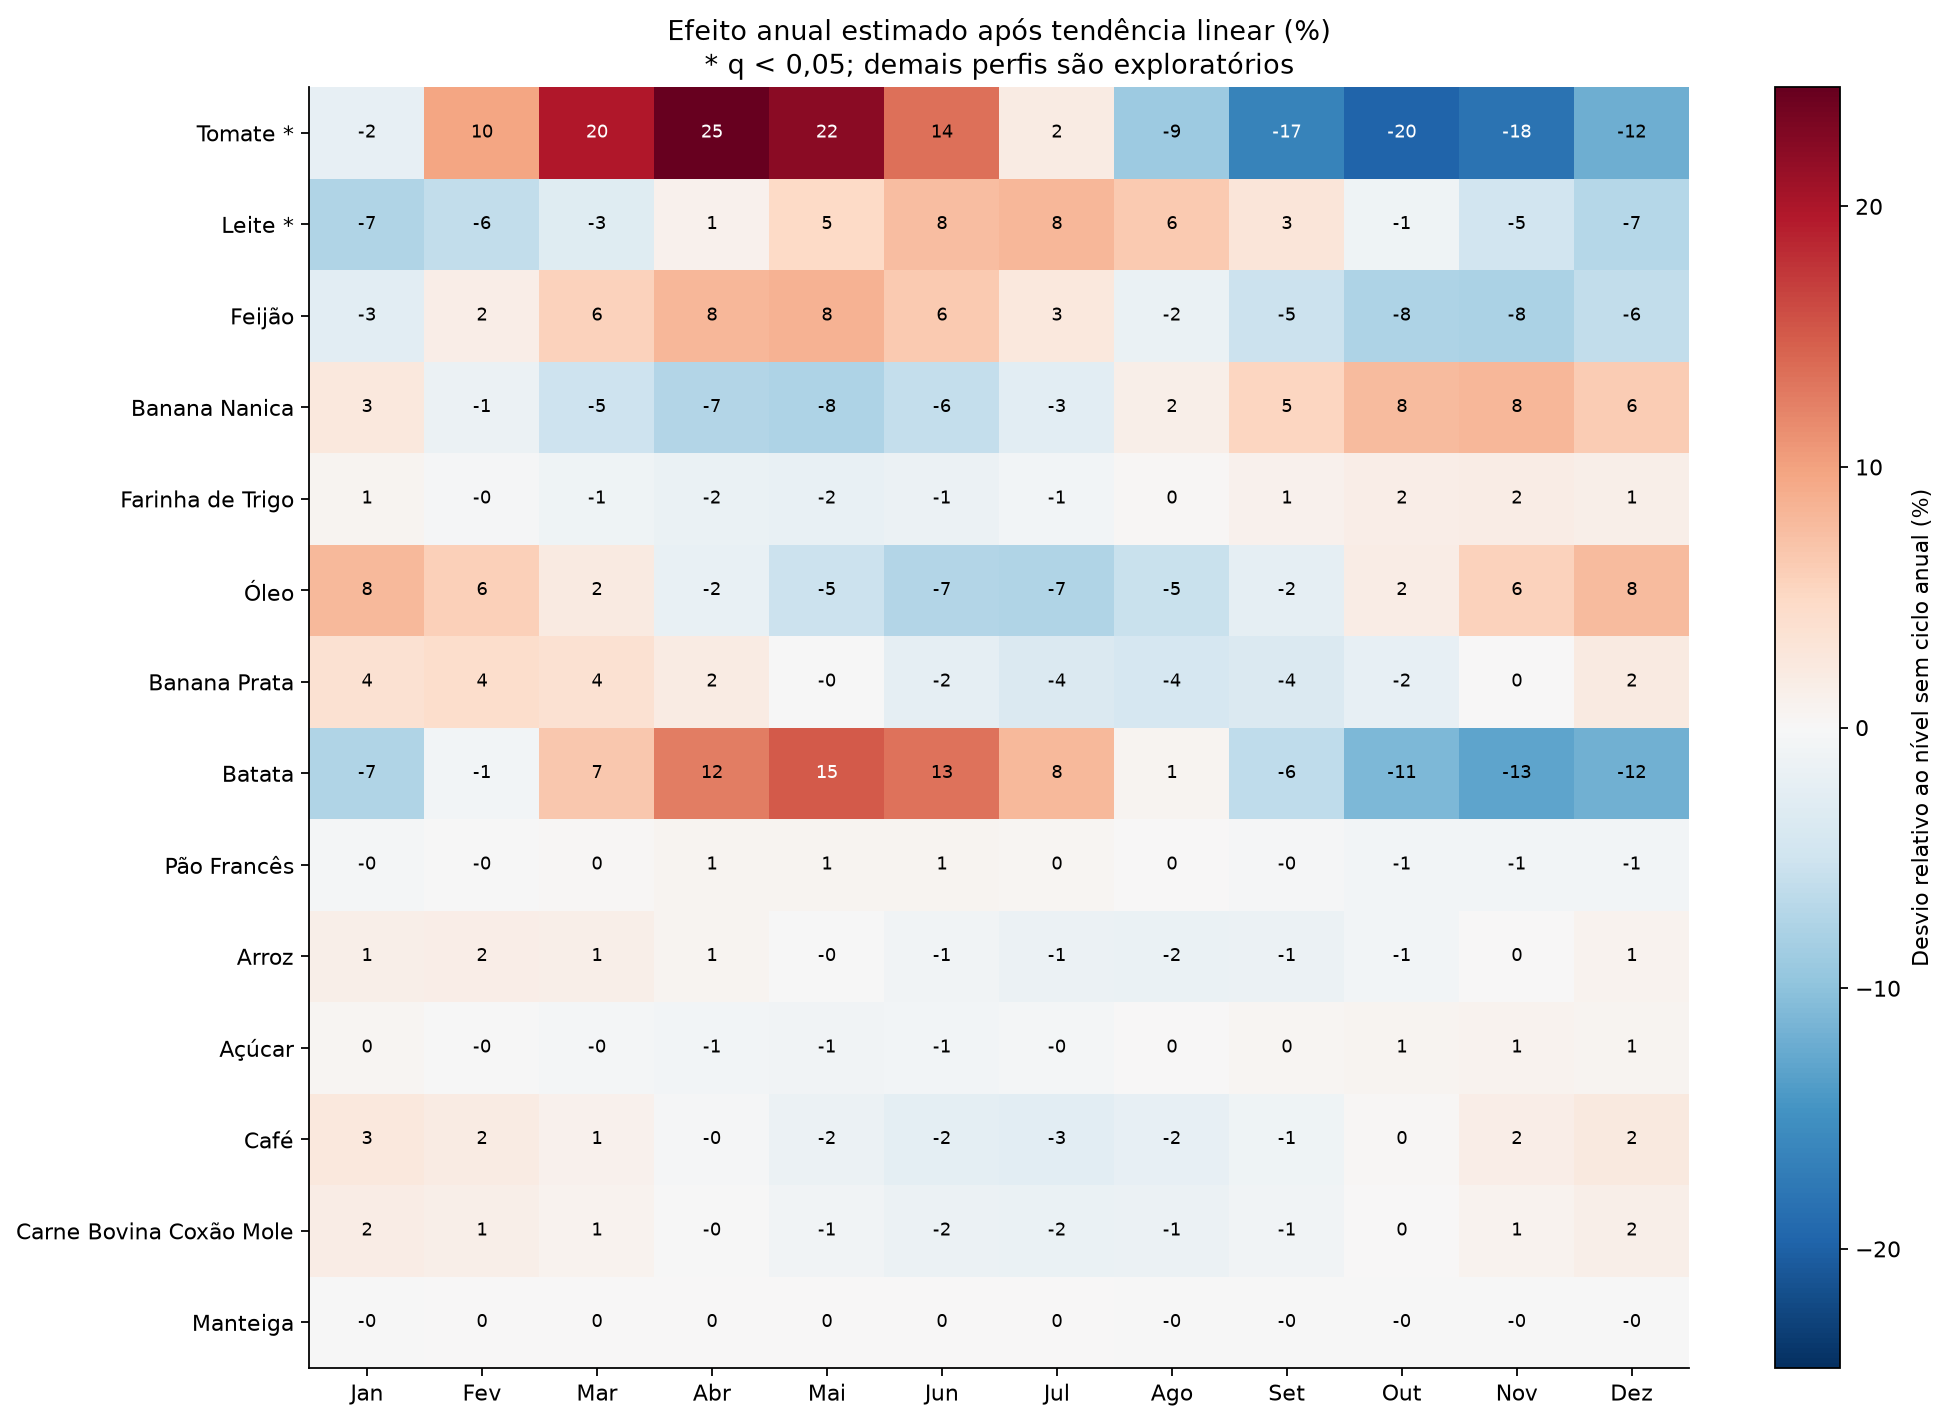

In [5]:
display(perfis.round(3))
display(Image(filename=str(FIG / "03_calendario_sazonal.png")))

## 5. Decomposição e repetição entre ciclos
STL robusta separa tendência, componente anual e resíduos em log-preços. A força STL é descritiva: não confirma sazonalidade sozinha. Os quatro produtos com menor q ilustram as decomposições e a comparação dos blocos setembro–agosto. As curvas normalizadas removem nível, mas preservam tendência dentro do bloco.

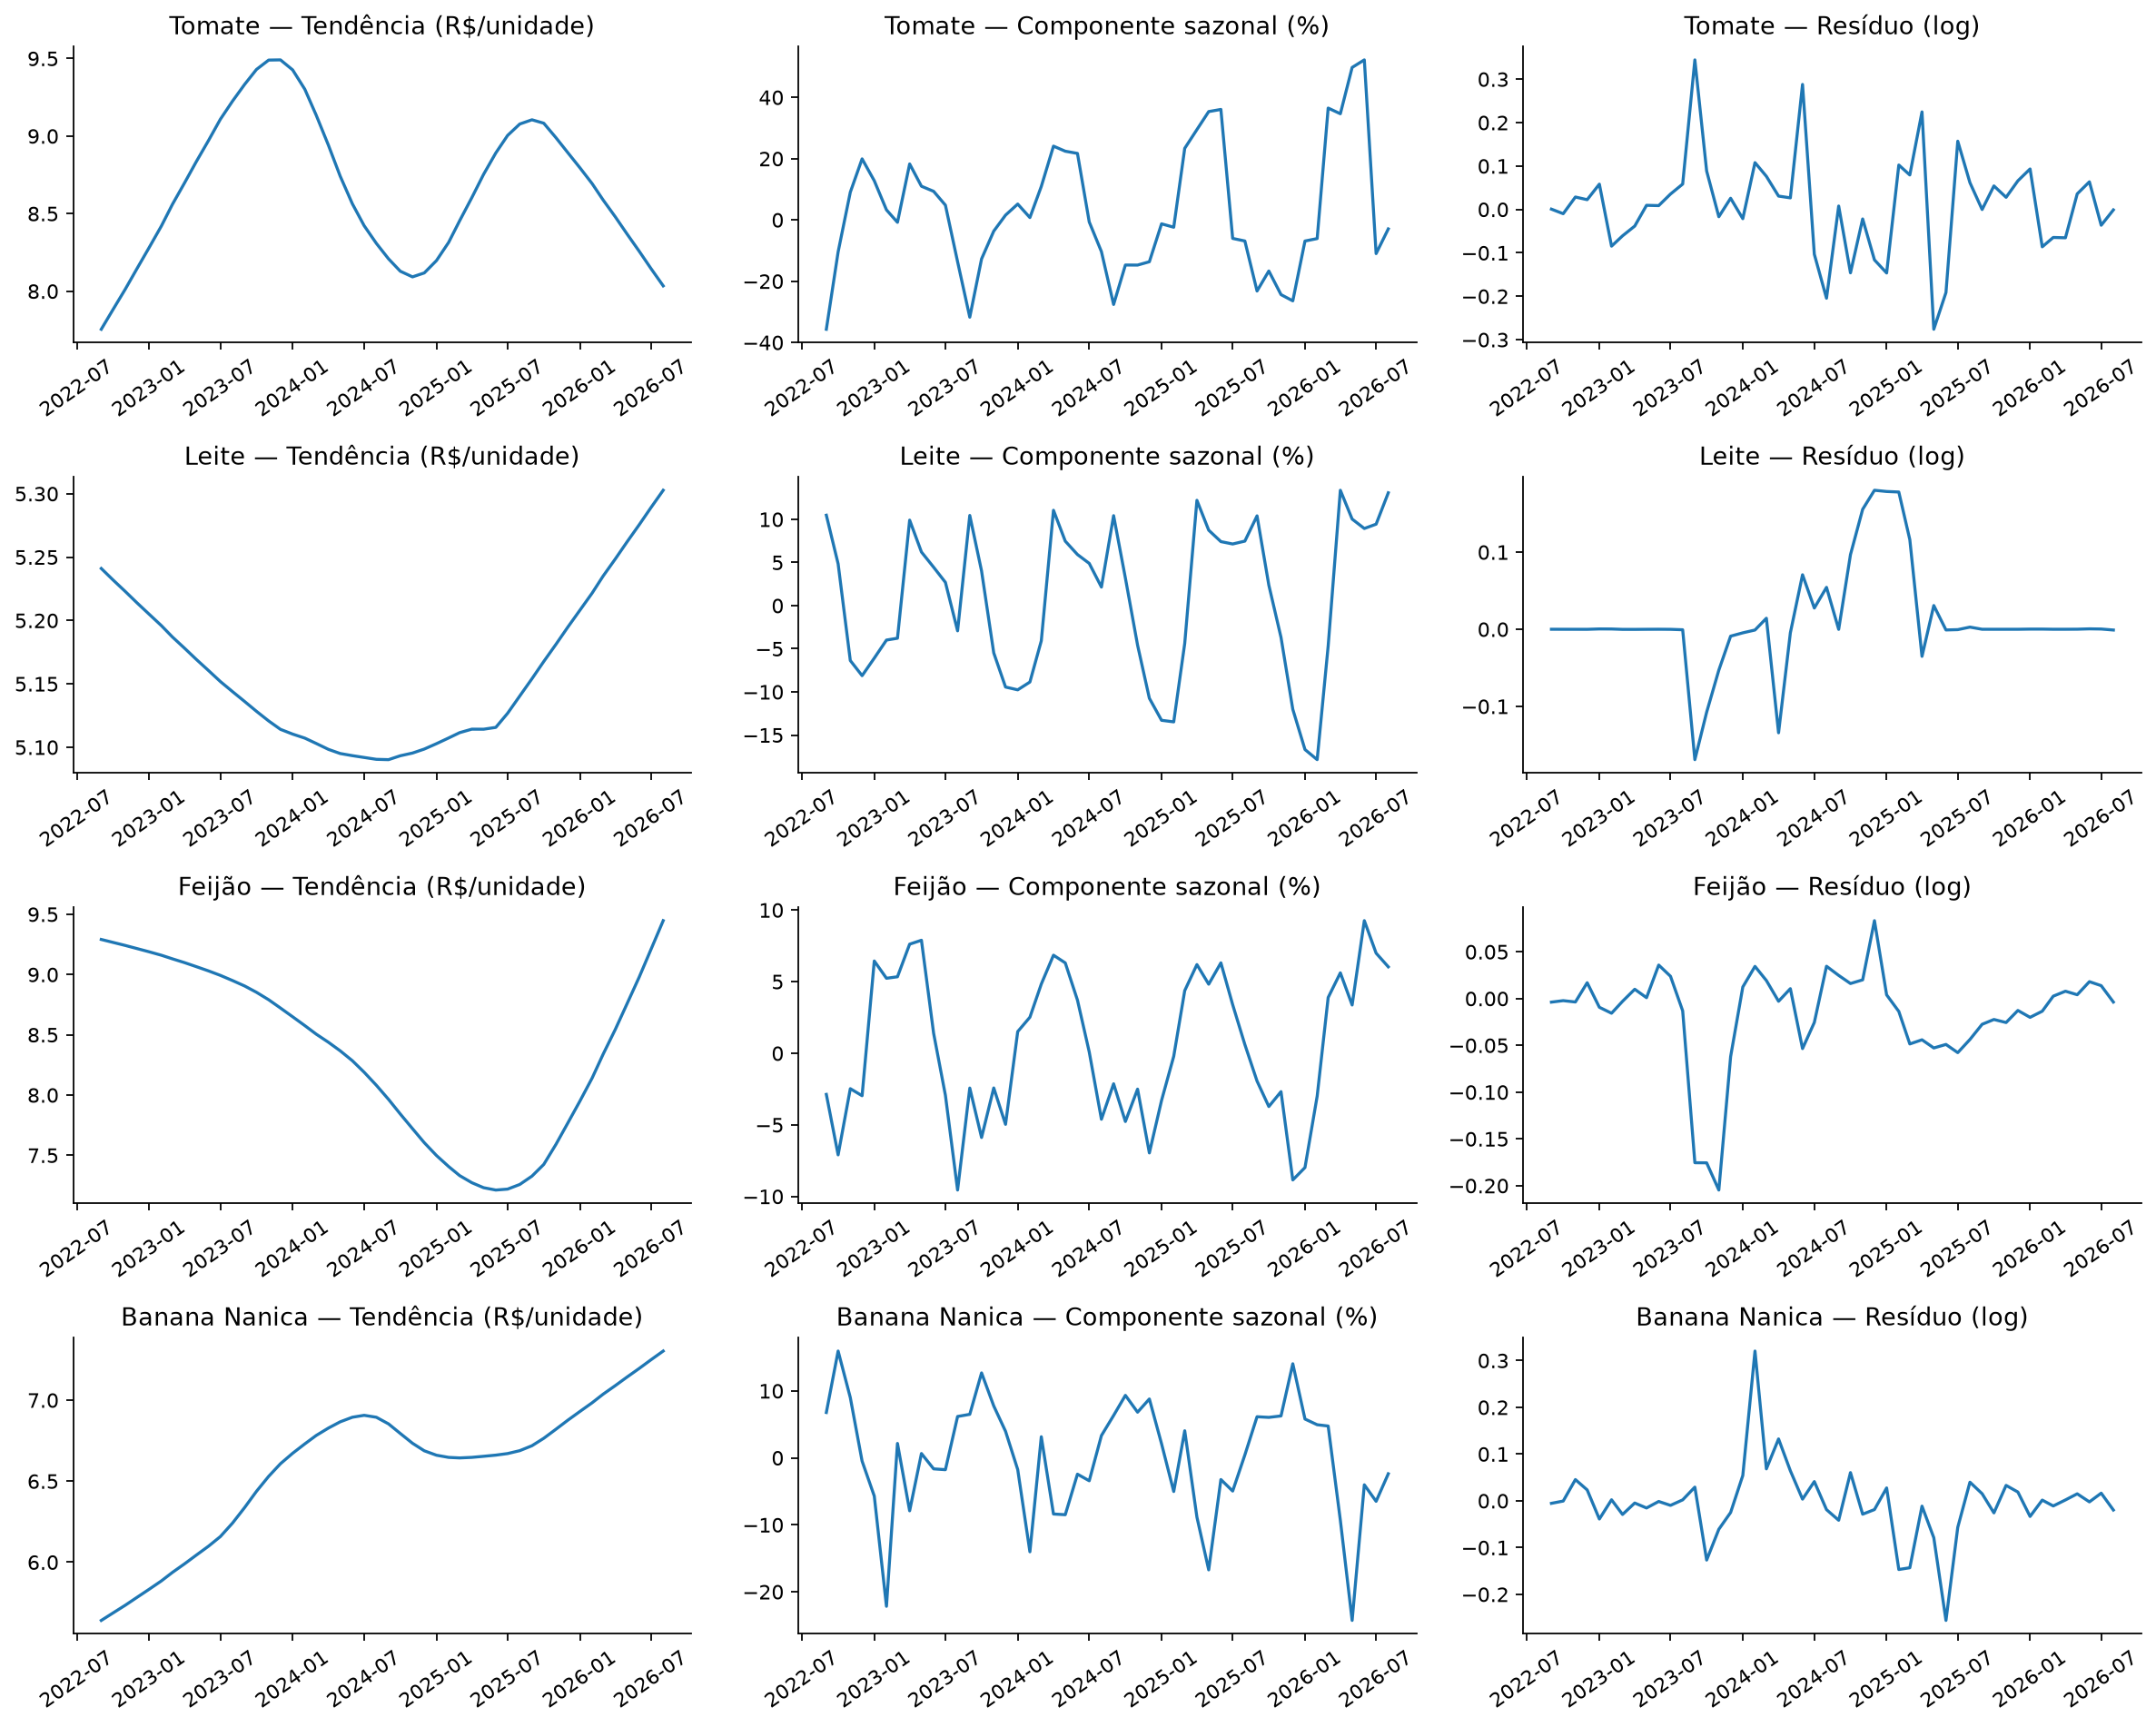

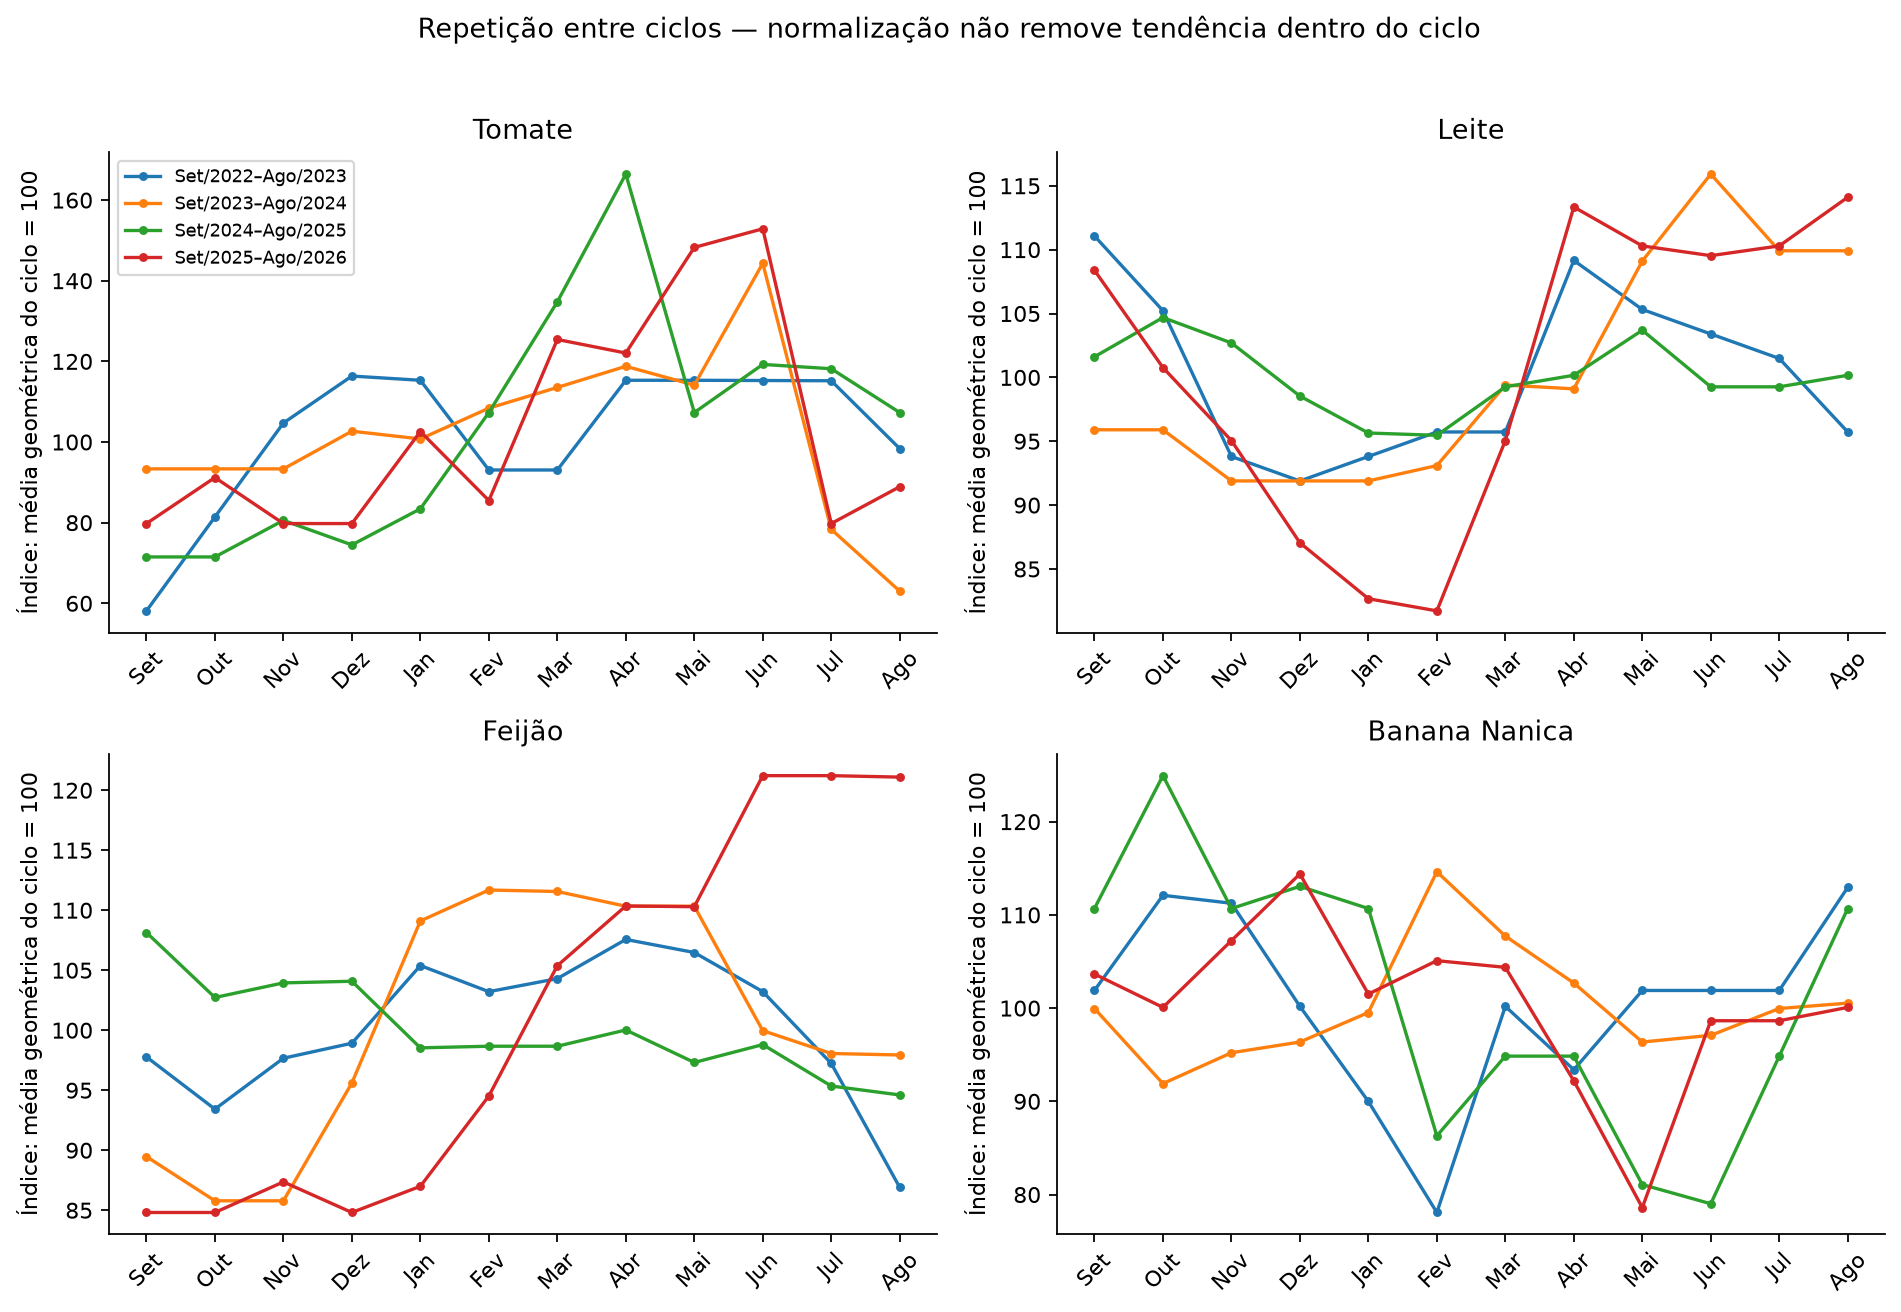

In [6]:
display(Image(filename=str(FIG / "05_decomposicao_stl.png")))
display(Image(filename=str(FIG / "06_comparacao_ciclos.png")))

## 6. Relatório, interpretação e conclusão

In [7]:
display(Markdown((OUT / "relatorio_sazonalidade.md").read_text(encoding="utf-8")))

# Análise de sazonalidade dos alimentos — Integrante 3

## Pergunta e conclusão
A época do ano influencia os preços? Nesta base, o teste do ciclo anual encontrou evidência de associação em **2 de 14 produtos elegíveis**, após correção de múltiplos testes (q < 0,05). Destes, **2** mantiveram o resultado nas duas verificações de sensibilidade. A conclusão é exploratória e específica dos produtos e estabelecimentos representados na base; não demonstra causalidade nem sazonalidade de toda a cesta brasileira.

Produtos com evidência no modelo principal: Tomate, Leite.

Produtos estáveis nas sensibilidades: Tomate, Leite.

## Base e cobertura
- Fonte: `data/processed/cesta_mensal.csv`, produzida na etapa anterior, sem alteração.
- Período: 09/2022 a 08/2026; 780 pares produto/mês; 20 produtos.
- Unidade de análise: mediana mensal do PPK (preço por kg ou unidade padrão do produto). Cada mês recebe o mesmo peso; coletas individuais não são tratadas como réplicas independentes.
- Critério definido antes dos testes: pelo menos 36 meses consecutivos, sem preenchimento de lacunas. Séries elegíveis: 14. Contagens observadas de meses por série elegível: 48.
- Séries fora da inferência pelo critério de cobertura: Carne Bovina Acém, Carne Suína Pernil, Frango Peito, Frango Sobrecoxa, Macarrão, Ovo. Seus valores permanecem nas tabelas descritivas.
- Preços nominais, sem correção por inflação. A tendência estatística não equivale a um deflator.

## Métodos
1. Auditoria de duplicatas, ausências, preços positivos, regularidade e contagens; tabelas de preços por mês do calendário e por ano. Médias anuais de 2022 e 2026 são parciais e não permitem comparação direta de anos completos.
2. Regressão por produto: `log(PPK) = constante + tendência linear + b_sen × sen(2π(mês−1)/12) + b_cos × cos(2π(mês−1)/12) + erro`. O tempo é centralizado e escalado entre −1 e 1. A hipótese nula conjunta é `b_sen = b_cos = 0`.
3. Teste Wald assintótico com covariância HAC (3 defasagens, correção de amostra). Correção Benjamini–Hochberg entre os 14 produtos, com limiar q < 0,05. O ciclo harmônico testa um padrão anual suave; não cobre todo formato possível de sazonalidade.
4. Sensibilidades: tendência quadrática e HAC com 6 defasagens, cada uma com correção BH própria. “Estável” exige q < 0,05 nos três ajustes; não é prova definitiva.
5. STL robusta em log-preços, período 12 e janela sazonal 13, separa tendência, sazonalidade e resíduos. Força descritiva: `max(0, 1 − Var(resíduo)/Var(sazonal + resíduo))`. STL extrai um componente mesmo sem significância; sua força não é teste estatístico.
6. Ljung–Box dos resíduos em 12 defasagens é diagnóstico exploratório (sem correção de multiplicidade ou ajuste pelos regressores). Dependência residual reduz a confiança na inferência de amostra pequena.

## Períodos de maior e menor preço
Os meses abaixo são extremos do **ciclo ajustado**, não os extremos brutos de um ano específico. A amplitude é `100 × (exp(pico_log − vale_log) − 1)`. Os índices mensais são relativos ao nível previsto sem o componente anual. Para produtos sem q < 0,05, os meses são apenas descrições do ajuste e **não sustentam recomendação de compra**. Não foram calculados intervalos para a localização do pico; meses vizinhos podem ser indistinguíveis.

| Produto | Vale estimado | Pico estimado | Pico/vale − 1 | q (BH) | Estável nas sensibilidades |
| --- | --- | --- | --- | --- | --- |
| Tomate | Out | Abr | 55.2% | 0.0003631 | Sim |
| Leite | Jan | Jul | 16.8% | 0.02037 | Sim |
| Feijão | Nov | Mai | 17.7% | 0.0511 | Não |
| Banana Nanica | Mai | Nov | 16.9% | 0.07253 | Não |
| Farinha de Trigo | Mai | Nov | 3.5% | 0.09065 | Não |
| Óleo | Jul | Jan | 16.4% | 0.249 | Não |
| Banana Prata | Ago | Fev | 8.8% | 0.3227 | Não |
| Batata | Nov | Mai | 32.3% | 0.3524 | Não |
| Pão Francês | Nov | Mai | 1.5% | 0.9555 | Não |
| Arroz | Ago | Fev | 3.4% | 0.983 | Não |
| Açúcar | Mai | Nov | 1.6% | 0.983 | Não |
| Café | Jul | Jan | 5.2% | 0.983 | Não |
| Carne Bovina Coxão Mole | Jul | Jan | 3.5% | 0.983 | Não |
| Manteiga | Nov | Mai | 0.3% | 0.983 | Não |

## Discussão dos resultados observados
- **Tomate:** pico ajustado em Abr e vale em Out, com diferença estimada de 55.2% entre pico e vale. q principal = 0.0003631; q com tendência quadrática = 0.0006524; q com HAC(6) = 0.00416. O diagnóstico não rejeita ausência de autocorrelação até a defasagem 12; isso não prova independência.
- **Leite:** pico ajustado em Jul e vale em Jan, com diferença estimada de 16.8% entre pico e vale. q principal = 0.02037; q com tendência quadrática = 0.01686; q com HAC(6) = 0.03586. Há autocorrelação residual no diagnóstico (p < 0,05), exigindo cautela adicional mesmo com HAC.
- **Resultados próximos ao limiar:** Feijão (q = 0.051), Banana Nanica (q = 0.073), Farinha de Trigo (q = 0.091). Não são classificados como evidência no teste principal, ainda que alguma especificação alternativa seja significativa.

O diagnóstico Ljung–Box apresentou p < 0,05 em 12 das 14 séries. Isso indica que a regressão simples deixa dependência temporal em parte dos resíduos. Por esse motivo, os resultados são apresentados como evidência exploratória, não como confirmação definitiva. As sensibilidades ajudam a avaliar estabilidade, mas não substituem mais anos de observação ou modelos de erros temporais mais completos.

## Interpretação dos gráficos
- **01 — Cobertura:** mostra a quantidade de meses observados e distingue séries elegíveis pela cor.
- **02 — Evolução e tendência:** permite separar movimentos persistentes de oscilações de curto prazo. Escalas são próprias por produto, portanto alturas absolutas entre painéis não são comparáveis.
- **03 — Calendário sazonal:** azul representa preço abaixo do nível sem ciclo; vermelho, acima. Asterisco identifica evidência após BH. É uma estimativa suavizada, não uma média bruta.
- **04 — Amplitudes:** compara oscilações em termos percentuais. Amplitude elevada, isoladamente, não implica significância.
- **05 — STL:** exibe os quatro menores q do modelo principal, escolhidos para ilustração. Picos nos resíduos são movimentos que tendência e sazonalidade não explicam.
- **06 — Ciclos:** compara esses mesmos produtos em blocos completos setembro–agosto. Curvas divergentes indicam instabilidade entre anos; a normalização remove nível, mas não tendência dentro de cada bloco.

## Limitações e resposta à pesquisa
Há apenas quatro ciclos anuais: os testes HAC são aproximações assintóticas e podem ser instáveis em 48 observações. Tendências não lineares, choques de oferta e alterações na composição das coletas podem parecer sazonalidade. A regressão harmônica impõe um pico e um vale anuais; ausência de significância não prova ausência de outros padrões. A correção BH controla a taxa esperada de falsas descobertas sob suas condições usuais, não elimina erros individuais nem resolve toda dependência entre produtos.

A época do ano apresenta associação estatística com preços nos produtos destacados, condicionada ao modelo. Os resultados que resistem às sensibilidades são os candidatos mais consistentes para discussão. Não se pode atribuir o padrão a safra, clima ou demanda sem variáveis externas. Não se prevê preço futuro nem se garante economia em determinado mês. As séries curtas precisam de mais ciclos antes de uma conclusão sazonal confiável.

## Reprodução e entregas
Na raiz do repositório, instale as dependências de `requirements.txt` e execute `python src/sazonalidade.py`, ou execute `notebooks/03_sazonalidade.ipynb` de cima para baixo. O notebook usa o mesmo módulo para evitar divergência entre os resultados.

As saídas ficam exclusivamente em `reports/sazonalidade/` e `reports/figures/sazonalidade/`. O manifesto registra o hash da entrada, parâmetros e versões. As tabelas CSV incluem cobertura, resumo anual, resumo mensal bruto, perfis ajustados, testes e componentes STL.

## Referências dos métodos
- [STL e seus parâmetros — statsmodels](https://www.statsmodels.org/stable/generated/statsmodels.tsa.seasonal.STL.html).
- [Regressão OLS e inferência — statsmodels](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.OLSResults.html).
- [Correção de testes múltiplos — statsmodels](https://www.statsmodels.org/stable/generated/statsmodels.stats.multitest.multipletests.html).


## 7. Rastreabilidade
O manifesto registra o hash do arquivo de entrada e as versões usadas. Nenhum arquivo das entregas anteriores é alterado pelo módulo.

In [8]:
display(Markdown("```json\n" + (OUT / "manifesto.json").read_text(encoding="utf-8") + "\n```"))

```json
{
  "entrada": "data/processed/cesta_mensal.csv",
  "sha256": "2cfc41a886826846205fedec5e5cace5dfac263139ddb9e799a4d0f3f7d6418a",
  "minimo_meses": 36,
  "periodo": 12,
  "janela_stl": 13,
  "hac_principal": 3,
  "hac_sensibilidade": 6,
  "alpha": 0.05,
  "ajuste": "fdr_bh",
  "python": "3.14.8",
  "pandas": "3.1.1",
  "numpy": "2.5.5",
  "scipy": "1.18.1",
  "statsmodels": "0.15.0",
  "matplotlib": "3.11.2"
}
```